# UTS Data Acquisition & Management — UTS_DAM_2501010174
**Topik:** Statistik pariwisata Bali per kabupaten/kota (Disparda Bali) + cuaca (Open-Meteo) + tabel statis situs publik  
**Alur:** (a) berkas dataset Disparda → (b) API Open-Meteo → (c) scraping halaman statis → merge → visual  
Struktur: `data/raw` (mentah, tidak diubah) · `Process` (hasil olah) · `docs` (provenance, checklist, bukti robots.txt)

## 0. Konfigurasi & fungsi bantu
**Sebelum menjalankan:**
1. Notebook meminta **email kampus** Anda (untuk User-Agent). Jika belum punya email kampus, minta ke BAAK/dosen atau konfirmasikan ke dosen email lain yang boleh dipakai; notebook hanya memberi peringatan, tidak memblokir.
2. Unduh dari halaman *Buku Statistik Pariwisata Bali 2025* (disparda.baliprov.go.id) **berkas Excel yang memuat tabel per kabupaten/kota**, misalnya `Table-13-23-Final` atau `Table-24-31-Final` (akomodasi, bar, restoran, kunjungan per kabupaten). **Jangan** memakai `Table-1-7` karena sheet pertamanya hanya daftar asosiasi (nama direktur, alamat, telepon) tanpa angka per wilayah.
3. Jalankan semua sel dari atas ke bawah (Runtime → Run all), lalu unggah berkas saat diminta.

In [ ]:
import os, re, io, sys, json, time, hashlib, datetime as dt
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

try:
    from dotenv import load_dotenv
    load_dotenv()                      # membaca .env (tidak ikut di-upload)
except ImportError:
    pass

# ---------- Identitas ----------
NAMA = "Francesco Nera Alfi Nanggor"
KELAS, PRODI = "F", "Informatika (Management Data Analyst)"
NIM = "2501010174"
IN_COLAB = "google.colab" in sys.modules

# ---------- Email kampus untuk User-Agent (Petunjuk 2: email kampus sendiri, bukan Gmail) ----------
EMAIL = os.getenv("EMAIL_KAMPUS", "").strip()
def email_valid(e):
    return bool(re.fullmatch(r"[\w.+-]+@[\w-]+(\.[\w-]+)+", e))
while not email_valid(EMAIL):
    EMAIL = input("Masukkan email kampus Anda (jika belum punya, isi email yang dipakai di ELSA/INSTIKI): ").strip()
if re.search(r"@(gmail|yahoo|ymail|hotmail|outlook|icloud|proton)", EMAIL, re.I):
    # Petunjuk 2 meminta email kampus. Peringatan ini mengingatkan agar dikonfirmasi ke dosen.
    print("PERINGATAN: email ini bukan email kampus. Petunjuk 2 soal meminta email kampus; konfirmasikan ke dosen.")

UA = f"INSTIKI-BIFP243-UTS/1.0 ({EMAIL}; {NAMA}; NIM {NIM})"
TIMEOUT, JEDA = 15, 2.0          # timeout detik & jeda antar-request (detik)

# ---------- Folder ----------
RAW, PROC, DOCS = Path("data/raw"), Path("Process"), Path("docs")
for p in (RAW, PROC, DOCS):
    p.mkdir(parents=True, exist_ok=True)

# ---------- Daftar wilayah Bali & fungsi normalisasi kunci merge ----------
BALI = ["jembrana", "tabanan", "badung", "denpasar", "gianyar", "klungkung", "bangli", "karangasem", "buleleng"]
ALIAS = {"amlapura": "karangasem", "singaraja": "buleleng", "semarapura": "klungkung"}

def wil(x):
    # Mengembalikan nama kab/kota Bali ternormalisasi, atau None.
    # Hanya sel pendek (<=35 karakter) yang dicocokkan agar alamat/kalimat panjang tidak ikut terdeteksi.
    t = str(x).strip().lower()
    if len(t) > 35:
        return None
    t = re.sub(r"\[.*?\]", "", t)
    for b in BALI:
        if b in t:
            return b
    for k, v in ALIAS.items():
        if k in t:
            return v
    return None

def to_num(x):
    # Mengubah sel menjadi float; menangani format Indonesia (1.234,5) dan catatan kaki [1].
    if isinstance(x, (int, float, np.number)):
        return float(x)
    s = re.sub(r"\[.*?\]", "", str(x)).strip().replace("\xa0", "").replace(" ", "")
    s = re.sub(r"[^\d,.\-]", "", s)
    if not s or s in ("-", ".", ","):
        return np.nan
    if re.fullmatch(r"-?\d{1,3}(\.\d{3})+(,\d+)?", s):
        s = s.replace(".", "").replace(",", ".")
    elif "," in s and "." not in s:
        s = s.replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return np.nan

# ---------- Provenance ----------
PROV_FILE = DOCS / "provenance.csv"
def md5_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(8192), b""):
            h.update(blok)
    return h.hexdigest()

def catat_provenance(nama, url, path, lisensi, metode):
    baris = {"sumber": nama, "url": url, "tanggal_akses": dt.datetime.now().isoformat(timespec="seconds"),
             "lisensi": lisensi, "metode": metode, "berkas": str(path),
             "ukuran_byte": Path(path).stat().st_size, "md5": md5_file(path)}
    df = pd.DataFrame([baris])
    if PROV_FILE.exists():
        lama = pd.read_csv(PROV_FILE)
        df = pd.concat([lama[lama["sumber"] != nama], df], ignore_index=True)   # satu baris per sumber
    df.to_csv(PROV_FILE, index=False)
    return baris

# ---------- Request sopan: timeout + User-Agent + jeda + retry ----------
def get_sopan(url, params=None, maks_coba=4):
    for i in range(1, maks_coba + 1):
        try:
            r = requests.get(url, params=params, headers={"User-Agent": UA}, timeout=TIMEOUT)
            if r.status_code == 200:
                time.sleep(JEDA)
                return r
            if r.status_code in (429, 500, 502, 503, 504):      # layak di-retry
                tunggu = 2 ** i
                print(f"  status {r.status_code}, retry {i}/{maks_coba} dalam {tunggu}s")
                time.sleep(tunggu)
                continue
            print(f"  status {r.status_code} -> berhenti (tidak di-retry)")
            r.raise_for_status()
        except (requests.Timeout, requests.ConnectionError) as e:
            tunggu = 2 ** i
            print(f"  {type(e).__name__}, retry {i}/{maks_coba} dalam {tunggu}s")
            time.sleep(tunggu)
    raise RuntimeError(f"Gagal mengambil {url}")

# ---------- Pemeriksaan robots.txt (dipakai untuk bukti kepatuhan) ----------
def cek_robots(url):
    p = urlparse(url)
    url_robots = f"{p.scheme}://{p.netloc}/robots.txt"
    bukti = {"url": url, "url_robots_txt": url_robots,
             "waktu_cek": dt.datetime.now().isoformat(timespec="seconds"), "user_agent": UA}
    try:
        r = requests.get(url_robots, headers={"User-Agent": UA}, timeout=TIMEOUT)
        time.sleep(JEDA)
        bukti["status_robots_txt"] = r.status_code
        if r.status_code == 200:
            rp = RobotFileParser()
            rp.parse(r.text.splitlines())
            bukti["boleh_diakses"] = bool(rp.can_fetch(UA, url))
            bukti["crawl_delay"] = rp.crawl_delay(UA)
            bukti["isi_robots_txt_cuplikan"] = r.text[:600]
        else:
            bukti["boleh_diakses"] = (r.status_code == 404)     # 404 = tidak ada aturan; selain itu dianggap tidak boleh
            bukti["crawl_delay"] = None
    except requests.RequestException as e:
        bukti["boleh_diakses"] = False
        bukti["error"] = f"{type(e).__name__}: {e}"
    return bukti

print("UA:", UA)

Masukkan email kampus Anda (jika belum punya, isi email yang dipakai di ELSA/INSTIKI): alfinanggor@gmail.com
PERINGATAN: email ini bukan email kampus. Petunjuk 2 soal meminta email kampus; konfirmasikan ke dosen.
UA: INSTIKI-BIFP243-UTS/1.0 (alfinanggor@gmail.com; Francesco Nera Alfi Nanggor; NIM 2501010174)


### Akuisisi (a): berkas dataset statistik pariwisata Bali
Berkas Excel diunduh manual dari portal resmi Dinas Pariwisata Provinsi Bali lalu diunggah. Berkas mentah disimpan apa adanya di `data/raw`. Pada sel berikutnya (Soal 1) notebook memindai **semua sheet**, mencari baris yang berisi nama kabupaten/kota Bali, dan memastikan syarat **minimal 100 baris** dan **minimal 5 kabupaten/kota** terpenuhi. Data tidak dibuat-buat; bila syarat tidak terpenuhi notebook berhenti dengan pesan yang jelas.

In [ ]:
URL_REKOMENDASI = "https://disparda.baliprov.go.id/buku-statistik-pariwisata-bali-tahun-2025"
print("Halaman sumber resmi:", URL_REKOMENDASI)
print("Unduh berkas Excel yang memuat tabel PER KABUPATEN/KOTA).")

kandidat_file = [p for p in RAW.iterdir() if p.suffix.lower() in (".csv", ".xls", ".xlsx")]
if kandidat_file:
    DATASET_FILE = kandidat_file[0]
    print("Memakai berkas yang sudah ada di data/raw:", DATASET_FILE.name)
elif IN_COLAB:
    from google.colab import files
    unggah = files.upload()
    if not unggah:
        raise RuntimeError("Belum ada dataset yang diunggah.")
    nama_f = next(iter(unggah))
    DATASET_FILE = RAW / nama_f
    DATASET_FILE.write_bytes(unggah[nama_f])
else:
    raise RuntimeError("Letakkan satu file CSV/Excel di folder data/raw terlebih dahulu.")

# URL berkas yang diunduh (tempel dari tautan unduhan) dan ketentuan penggunaan portal
DATASET_URL = input("Tempel URL berkas/halaman dataset yang diunduh (Enter = halaman Buku Statistik 2025): ").strip() or URL_REKOMENDASI
DATASET_SUMBER = "Dinas Pariwisata Provinsi Bali - Statistik Pariwisata Bali 2025"
DATASET_LISENSI = ("Hak cipta Pemerintah Provinsi Bali; dilarang mereproduksi/menggandakan isi buku untuk tujuan komersial "
                   "tanpa izin tertulis. Dipakai non-komersial untuk tugas kuliah dengan mencantumkan sumber.")
print("Berkas:", DATASET_FILE.name, "| URL:", DATASET_URL)

Halaman sumber resmi: https://disparda.baliprov.go.id/buku-statistik-pariwisata-bali-tahun-2025
Unduh berkas Excel yang memuat tabel PER KABUPATEN/KOTA).


Saving Table-24-31-Final-5 (1).xls to Table-24-31-Final-5 (1).xls
Tempel URL berkas/halaman dataset yang diunduh (Enter = halaman Buku Statistik 2025): https://cloud-ng.baliprov.go.id/disparda/2026/04/Table-24-31-Final-5.xls
Berkas: Table-24-31-Final-5 (1).xls | URL: https://cloud-ng.baliprov.go.id/disparda/2026/04/Table-24-31-Final-5.xls


## Soal 1 — Baca berkas, identifikasi dataset, estimasi storage
**Parameter pembacaan** (berkas tabel statistik Disparda memiliki judul, header bertingkat, dan catatan kaki, sehingga dibaca mentah lalu disusun ulang):
- `sheet_name=None` → semua sheet dibaca, `header=None` → baris judul/header tidak dianggap nama kolom.
- `na_values=["-", "--", "NA", "n/a", "N/A", ""]` → penanda data kosong.
- Header kolom disusun dari maksimal 4 baris di atas baris wilayah pertama (pengganti `skiprows` yang adaptif per sheet); angka dikonversi dengan `to_num` (menangani format 1.234,5).
- Hasil: tabel **long** `tabel | wilayah | indikator | nilai`, satu baris per sel angka per kabupaten/kota.
Berkas asli tidak diubah.

In [ ]:
NA_VALUES = ["-", "--", "NA", "n/a", "N/A", ""]
ext = DATASET_FILE.suffix.lower()

# ---- 1. Baca berkas mentah (semua sheet) ----
if ext in (".xls", ".xlsx"):
    lembar = pd.read_excel(DATASET_FILE, sheet_name=None, header=None, na_values=NA_VALUES)
else:
    lembar = None
    for enc in ("utf-8", "latin-1"):
        try:
            lembar = {DATASET_FILE.stem: pd.read_csv(DATASET_FILE, sep=None, engine="python", header=None,
                                                     encoding=enc, na_values=NA_VALUES)}
            print("encoding terpakai:", enc)
            break
        except Exception:
            continue
    if lembar is None:
        raise ValueError("CSV tidak dapat dibaca dengan encoding utf-8 maupun latin-1.")

# ---- 2. Ubah tiap sheet menjadi tabel long per kabupaten/kota ----
def label_kolom(raw, first_row, c):
    # Gabungkan teks header dari <=4 baris di atas baris wilayah pertama (baris judul 1 sel diabaikan).
    bagian = []
    for r in range(max(0, first_row - 4), first_row):
        baris = raw.iloc[r]
        if baris.notna().sum() >= 2:
            v = baris.ffill().iloc[c]
            if pd.notna(v):
                v = int(v) if isinstance(v, float) and float(v).is_integer() else v
                v = str(v).strip()
                if v and v not in bagian:
                    bagian.append(v)
    return " | ".join(bagian) if bagian else f"kolom_{c}"

def parse_sheet(raw, nama):
    raw = raw.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
    raw.columns = range(raw.shape[1])
    baris_wil = []
    for i in range(len(raw)):
        for j in range(raw.shape[1]):
            v = raw.iat[i, j]
            if isinstance(v, str) and wil(v):
                baris_wil.append((i, j, wil(v)))
                break
    if len(baris_wil) < 3:
        return None, None
    first = baris_wil[0][0]
    out = []
    for c in raw.columns:
        nilai = []
        for i, j, w in baris_wil:
            nilai.append(np.nan if c == j else to_num(raw.at[i, c]))
        s = pd.Series(nilai, dtype="float64")
        if s.notna().sum() < 3:
            continue
        lab = label_kolom(raw, first, c)
        if re.match(r"^(no|nomor|kode)\b", lab, re.I) or (s.notna().sum() >= 3 and np.allclose(s.dropna().values, np.arange(1, s.notna().sum() + 1))):
            continue                                   # kolom nomor urut bukan indikator
        for (i, j, w), v in zip(baris_wil, nilai):
            if not np.isnan(v):
                out.append({"tabel": nama, "wilayah": w, "indikator": lab, "nilai": v, "baris_sumber": i})
    teks_atas = [str(v).strip() for v in raw.iloc[:max(first, 1)].values.ravel() if isinstance(v, str) and len(v.strip()) > 12]
    judul = teks_atas[0] if teks_atas else nama
    satuan = next((m for t in teks_atas for m in re.findall(r"\(([^)]{2,40})\)", t)), "tidak tercantum pada judul tabel")
    return pd.DataFrame(out), {"judul": judul, "satuan": satuan}

potongan, META_SHEET = [], {}
for nama_sheet, raw in lembar.items():
    hasil, meta = parse_sheet(raw, str(nama_sheet))
    if hasil is not None and len(hasil):
        potongan.append(hasil)
        meta["n_wilayah"] = int(hasil["wilayah"].nunique())
        meta["n_baris"] = int(len(hasil))
        META_SHEET[str(nama_sheet)] = meta

if not potongan:
    raise ValueError("Tidak ada sheet yang memuat baris kabupaten/kota Bali. Berkas ini bukan tabel per wilayah "
                     "(mis. daftar asosiasi). Unduh berkas lain, misalnya Table-13-23-Final atau Table-24-31-Final "
                     "dari halaman Buku Statistik Pariwisata Bali 2025, lalu hapus berkas lama di data/raw.")
df_long = pd.concat(potongan, ignore_index=True)
print("Sheet terbaca:", len(lembar), "| sheet bermuatan wilayah:", len(META_SHEET))
display(pd.DataFrame(META_SHEET).T)

# ---- 3. Validasi syarat soal ----
n_wil = df_long["wilayah"].nunique()
assert len(df_long) >= 100, f"Dataset hanya {len(df_long)} baris (<100). Gunakan berkas dengan lebih banyak tabel/kolom tahun."
assert n_wil >= 5, f"Hanya {n_wil} kabupaten/kota terdeteksi (<5)."
print("Dimensi tabel long (baris, kolom):", df_long.shape, "| kabupaten/kota unik:", n_wil)
display(df_long.head(10))
display(df_long.dtypes.to_frame("tipe_data"))
catat_provenance("Dataset berkas", DATASET_URL, DATASET_FILE, DATASET_LISENSI, "Unduh manual (Excel/CSV)")

Sheet terbaca: 8 | sheet bermuatan wilayah: 4


,judul,satuan,n_wilayah,n_baris
TAB 24ok,RESTAURANT/RUMAH MAKAN IN BALI BY REGENCY IN 2...,tidak tercantum pada judul tabel,9,108
TAB 25ok,BAR IN BALI BY REGENCY IN 2019 - 2025,tidak tercantum pada judul tabel,9,63
TAB 29ok,"TOURIST RESORT, PLACES OF INTEREST,",tidak tercantum pada judul tabel,9,27
TAB 31ok,TABLE 31. LIST OF RURAL TOURISM IN BALI,tidak tercantum pada judul tabel,3,3


Dimensi tabel long (baris, kolom): (201, 5) | kabupaten/kota unik: 9


,tabel,wilayah,indikator,nilai,baris_sumber
0,TAB 24ok,denpasar,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,604.0,5
1,TAB 24ok,badung,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,823.0,6
2,TAB 24ok,bangli,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,47.0,7
3,TAB 24ok,buleleng,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,200.0,8
4,TAB 24ok,gianyar,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,952.0,9
5,TAB 24ok,jembrana,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,136.0,10
6,TAB 24ok,klungkung,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,245.0,11
7,TAB 24ok,karangasem,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,146.0,12
8,TAB 24ok,tabanan,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,80.0,13
9,TAB 24ok,denpasar,RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABU...,34336.0,5


,tipe_data
tabel,object
wilayah,object
indikator,object
nilai,float64
baris_sumber,int64


{'sumber': 'Dataset berkas',
 'url': 'https://cloud-ng.baliprov.go.id/disparda/2026/04/Table-24-31-Final-5.xls',
 'tanggal_akses': '2026-11-27T05:32:27',
 'lisensi': 'Hak cipta Pemerintah Provinsi Bali; dilarang mereproduksi/menggandakan isi buku untuk tujuan komersial tanpa izin tertulis. Dipakai non-komersial untuk tugas kuliah dengan mencantumkan sumber.',
 'metode': 'Unduh manual (Excel/CSV)',
 'berkas': 'data/raw/Table-24-31-Final-5 (1).xls',
 'ukuran_byte': 129536,
 'md5': '2998c78893d9238bd3ca9d876795031d'}

In [ ]:
# Identifikasi dataset
ukuran_byte = DATASET_FILE.stat().st_size
ukuran_mb = ukuran_byte / 1024 / 1024
tahun = [int(y) for y in re.findall(r"\b(19\d{2}|20\d{2})\b", " ".join(df_long["indikator"].unique()))]
satuan_semua = sorted({m["satuan"] for m in META_SHEET.values()})
identitas = {
    "jenis_data": "Terstruktur (tabular Excel: baris=kabupaten/kota, kolom=indikator/tahun; skema tetap)",
    "jumlah_baris": df_long.shape[0], "jumlah_kolom": df_long.shape[1],
    "kolom_numerik": list(df_long.select_dtypes("number").columns),
    "kolom_teks": list(df_long.select_dtypes(exclude="number").columns),
    "ukuran_berkas_MB": round(ukuran_mb, 4),
    "cakupan_wilayah": f"{n_wil} kabupaten/kota Bali: " + ", ".join(sorted(df_long["wilayah"].str.title().unique())),
    "cakupan_waktu": f"{min(tahun)} s.d. {max(tahun)} (dari label kolom)" if tahun else "satu periode (tahun terbit buku: 2025)",
    "satuan": "; ".join(satuan_semua) + " (diambil dari judul tiap tabel)",
    "jumlah_tabel_terpakai": len(META_SHEET),
}
for k, v in identitas.items():
    print(f"{k:22}: {v}")

jenis_data            : Terstruktur (tabular Excel: baris=kabupaten/kota, kolom=indikator/tahun; skema tetap)
jumlah_baris          : 201
jumlah_kolom          : 5
kolom_numerik         : ['nilai', 'baris_sumber']
kolom_teks            : ['tabel', 'wilayah', 'indikator']
ukuran_berkas_MB      : 0.1235
cakupan_wilayah       : 9 kabupaten/kota Bali: Badung, Bangli, Buleleng, Denpasar, Gianyar, Jembrana, Karangasem, Klungkung, Tabanan
cakupan_waktu         : 2019 s.d. 2025 (dari label kolom)
satuan                : tidak tercantum pada judul tabel (diambil dari judul tiap tabel)
jumlah_tabel_terpakai : 4


In [ ]:
# Estimasi storage 1 tahun = ukuran berkas x 12 bulan, + cadangan 30%
CADANGAN = 0.30
dasar = ukuran_mb * 12
total = dasar * (1 + CADANGAN)
print(f"Ukuran berkas             : {ukuran_mb:.4f} MB")
print(f"x 12 bulan                : {dasar:.4f} MB")
print(f"+ cadangan {CADANGAN:.0%}            : {total:.4f} MB (= {total/1024:.6f} GB)")
estimasi = pd.DataFrame({"komponen": ["ukuran_berkas_MB", "x12_bulan_MB", "cadangan_30persen_MB", "total_1_tahun_MB"],
                         "nilai": [ukuran_mb, dasar, dasar * CADANGAN, total]})
estimasi.to_csv(DOCS / "estimasi_storage.csv", index=False)

Ukuran berkas             : 0.1235 MB
x 12 bulan                : 1.4824 MB
+ cadangan 30%            : 1.9271 MB (= 0.001882 GB)


**Asumsi estimasi storage:** (1) berkas diunduh ulang sekali per bulan dan setiap unduhan disimpan sebagai berkas terpisah berukuran sama dengan berkas sekarang; (2) tidak ada kompresi; (3) cadangan 30% untuk berkas olahan (CSV bersih, JSON, HTML), log, dan pertumbuhan data; (4) data API dan scraping tidak dihitung terpisah karena ukurannya jauh lebih kecil (ukuran tercatat di `docs/provenance.csv`).

## Soal 2 — Lisensi, PII/quasi-identifier, dan Data Ethics Checklist
Langkah: lisensi & ketentuan portal dicatat di provenance → seluruh sel berkas dipindai dengan pola PII (email, telepon, NIK) → kolom diklasifikasi → checklist 9 butir diisi dengan bukti. Tabel long hanya memuat nama wilayah, label indikator, dan angka agregat sehingga kolom kontak tidak terbawa (minimalisasi data).

In [ ]:
# Klasifikasi kolom tabel long + pemindaian pola PII pada SEMUA sel berkas mentah
POLA = {"email": r"[\w.+-]+@[\w-]+\.[\w.]+",
        "telepon": r"(?:\+62|\b0)8\d{8,11}\b|\(0\d{2,3}\)\s?\d{5,8}",
        "nik": r"\b\d{16}\b"}
temuan = {k: 0 for k in POLA}
for raw in lembar.values():
    teks = raw.stack().astype(str)
    for jenis, p in POLA.items():
        temuan[jenis] += int(teks.str.contains(p, regex=True).sum())
print("Sel berpola PII pada berkas mentah:", temuan)
ada_pii_mentah = any(v > 0 for v in temuan.values())

def mask_pii(teks):
    # Masking untuk teks yang masih mungkin berisi kontak (dipakai bila ada kolom teks bebas).
    for p in POLA.values():
        teks = re.sub(p, "[DISAMARKAN]", str(teks))
    return teks

klasifikasi = pd.DataFrame({
    "kolom": df_long.columns,
    "kategori": ["Non-PII (nama tabel/sheet)", "Non-PII (wilayah administratif, bukan individu)",
                 "Non-PII (label indikator)", "Non-PII (angka agregat)", "Non-PII (nomor baris sumber)"],
})
display(klasifikasi)
klasifikasi.to_csv(DOCS / "klasifikasi_pii.csv", index=False)

# Bukti: tabel long yang dipakai tidak memuat pola PII sama sekali
for kol in df_long.select_dtypes(exclude="number").columns:
    for jenis, p in POLA.items():
        assert not df_long[kol].astype(str).str.contains(p, regex=True).any(), f"PII ({jenis}) di kolom {kol}"
ada_pii_dipakai = False
print("PII pada tabel yang dipakai:", ada_pii_dipakai, "| quasi-identifier (alamat/koordinat/usia/gender): tidak ada")

Sel berpola PII pada berkas mentah: {'email': 0, 'telepon': 0, 'nik': 2}


,kolom,kategori
0,tabel,Non-PII (nama tabel/sheet)
1,wilayah,"Non-PII (wilayah administratif, bukan individu)"
2,indikator,Non-PII (label indikator)
3,nilai,Non-PII (angka agregat)
4,baris_sumber,Non-PII (nomor baris sumber)


PII pada tabel yang dipakai: False | quasi-identifier (alamat/koordinat/usia/gender): tidak ada


In [ ]:
# Data Ethics Checklist 9 butir (format Modul 4) - lengkap dengan bukti
bukti_robots_dataset = cek_robots(URL_REKOMENDASI)
(DOCS / "robots_check_dataset.json").write_text(json.dumps(bukti_robots_dataset, indent=2, ensure_ascii=False), encoding="utf-8")
print("robots.txt portal dataset -> status:", bukti_robots_dataset.get("status_robots_txt"), "| boleh:", bukti_robots_dataset["boleh_diakses"])

checklist = pd.DataFrame({
    "Aspek": ["Sumber data dan URL dicantumkan", "Lisensi data diperiksa dan dicatat",
              "robots.txt / Terms of Service diperiksa", "Kolom PII diidentifikasi",
              "PII dihapus, di-mask, atau di-pseudonimisasi", "Prinsip minimalisasi data diterapkan",
              "Potensi bias sampel dianalisis", "Tujuan penggunaan data dinyatakan eksplisit",
              "Rencana retensi dan penghapusan data ada"],
    "Status (Ya/Tidak/NA)": ["Ya", "Ya", "Ya", "Ya", "Ya" if ada_pii_mentah else "NA", "Ya", "Ya", "Ya", "Ya"],
    "Bukti / Catatan": [
        f"docs/provenance.csv memuat 3 sumber. Berkas: {DATASET_URL}; API: archive-api.open-meteo.com; scraping: lihat docs/scraping_meta.json",
        f"Dataset: {DATASET_LISENSI} | Open-Meteo: CC BY 4.0 (atribusi) | Situs scraping: lihat docs/robots_check.json dan metadata sumber resmi Disparda Bali.",
        "docs/robots_check_dataset.json (portal dataset) dan docs/robots_check.json (halaman scraping) berisi status robots.txt, hasil can_fetch, crawl-delay; User-Agent berisi email kampus",
        f"docs/klasifikasi_pii.csv; pemindaian pola email/telepon/NIK pada seluruh sel berkas: {temuan}",
        ("Sel berpola PII tidak dibawa ke tabel long (hanya wilayah, label, angka); assert pola PII = 0 lolos; fungsi mask_pii tersedia"
         if ada_pii_mentah else "Tidak ada PII pada berkas; assert pola PII = 0 lolos"),
        "Hanya kolom yang dibutuhkan: wilayah, indikator, nilai; API hanya suhu rata-rata & curah hujan harian; scraping maksimal 3 kolom angka",
        "Bias seleksi: 9 kab/kota Bali dan satu tahun terbit; data resmi dinas tidak mencakup usaha informal; cuaca diambil di titik ibu kota, bukan rata-rata wilayah; tahun berkas dan scraping dapat berbeda dengan 2025",
        "Tujuan: tugas UTS - menganalisis hubungan indikator pariwisata dengan kondisi wilayah dan cuaca; tidak komersial dan tidak untuk profiling individu",
        "Data mentah disimpan selama semester berjalan (sampai nilai final) lalu dihapus dari repo dan perangkat; hasil gabungan agregat boleh diarsipkan",
    ],
})
checklist.to_csv(DOCS / "data_ethics_checklist.csv", index=False)
display(checklist)

robots.txt portal dataset -> status: 200 | boleh: True


,Aspek,Status (Ya/Tidak/NA),Bukti / Catatan
0,Sumber data dan URL dicantumkan,Ya,docs/provenance.csv memuat 3 sumber. Berkas: h...
1,Lisensi data diperiksa dan dicatat,Ya,Dataset: Hak cipta Pemerintah Provinsi Bali; d...
2,robots.txt / Terms of Service diperiksa,Ya,docs/robots_check_dataset.json (portal dataset...
3,Kolom PII diidentifikasi,Ya,docs/klasifikasi_pii.csv; pemindaian pola emai...
4,"PII dihapus, di-mask, atau di-pseudonimisasi",Ya,Sel berpola PII tidak dibawa ke tabel long (ha...
5,Prinsip minimalisasi data diterapkan,Ya,"Hanya kolom yang dibutuhkan: wilayah, indikato..."
6,Potensi bias sampel dianalisis,Ya,Bias seleksi: 9 kab/kota Bali dan satu tahun t...
7,Tujuan penggunaan data dinyatakan eksplisit,Ya,Tujuan: tugas UTS - menganalisis hubungan indi...
8,Rencana retensi dan penghapusan data ada,Ya,Data mentah disimpan selama semester berjalan ...


## Soal 3 — Akuisisi via API (Open-Meteo, cuaca historis)
Portal sumber tidak menyediakan API terbuka yang praktis, maka dipakai **API publik Open-Meteo** (tanpa API key, sehingga tidak ada kunci di notebook) untuk cuaca harian 2025 di ibu kota 9 kabupaten/kota Bali. Status code dan retry ditangani `get_sopan`. Respons JSON mentah disimpan di `data/raw`, lalu dinormalisasi menjadi tabel (jauh di atas 30 baris).

In [ ]:
# Koordinat pendekatan ibu kota tiap kabupaten/kota (hanya untuk titik cuaca)
LOKASI = {
    "Jembrana": (-8.36, 114.62), "Tabanan": (-8.54, 115.12), "Badung": (-8.58, 115.18),
    "Denpasar": (-8.65, 115.22), "Gianyar": (-8.54, 115.33), "Klungkung": (-8.54, 115.40),
    "Bangli": (-8.45, 115.35), "Karangasem": (-8.45, 115.61), "Buleleng": (-8.11, 115.09),
}
API_URL = "https://archive-api.open-meteo.com/v1/archive"
MULAI, AKHIR = "2025-01-01", "2025-12-31"

baris_api = []
for wilayah, (lat, lon) in LOKASI.items():
    params = {"latitude": lat, "longitude": lon, "start_date": MULAI, "end_date": AKHIR,
              "daily": "temperature_2m_mean,precipitation_sum", "timezone": "Asia/Makassar"}
    r = get_sopan(API_URL, params=params)
    js = r.json()
    (RAW / f"cuaca_openmeteo_{wilayah.lower()}.json").write_text(json.dumps(js, ensure_ascii=False), encoding="utf-8")
    d = js["daily"]
    for t, suhu, hujan in zip(d["time"], d["temperature_2m_mean"], d["precipitation_sum"]):
        baris_api.append({"wilayah": wilayah, "tanggal": t, "suhu_rata2_C": suhu, "hujan_mm": hujan})
    print(f"{wilayah}: {len(d['time'])} hari")

cuaca_harian = pd.DataFrame(baris_api)                 # normalisasi JSON -> tabel
cuaca_harian["tanggal"] = pd.to_datetime(cuaca_harian["tanggal"])
assert len(cuaca_harian) >= 30
print("Tabel hasil normalisasi:", cuaca_harian.shape)
display(cuaca_harian.head())

# Provenance (satu berkas gabungan JSON agar md5 satu sumber; JSON per kabupaten tetap ada di data/raw)
gabung_json = RAW / "cuaca_openmeteo_semua.json"
gabung_json.write_text(json.dumps(baris_api, default=str, ensure_ascii=False), encoding="utf-8")
catat_provenance("API Open-Meteo", API_URL, gabung_json, "CC BY 4.0 (open-meteo.com/en/license)", "API JSON (tanpa key)")
cuaca_harian.to_csv(PROC / "cuaca_harian_bersih.csv", index=False)
(PROC / "cuaca_harian_bersih.json").write_text(cuaca_harian.to_json(orient="records", date_format="iso", force_ascii=False), encoding="utf-8")

Jembrana: 365 hari
Tabanan: 365 hari
Badung: 365 hari
Denpasar: 365 hari
Gianyar: 365 hari
Klungkung: 365 hari
Bangli: 365 hari
Karangasem: 365 hari
Buleleng: 365 hari
Tabel hasil normalisasi: (3285, 4)


,wilayah,tanggal,suhu_rata2_C,hujan_mm
0,Jembrana,2025-01-01,26.0,22.9
1,Jembrana,2025-01-02,25.0,15.5
2,Jembrana,2025-01-03,25.5,11.0
3,Jembrana,2025-01-04,24.9,11.7
4,Jembrana,2025-01-05,25.5,8.8


308410

In [ ]:
# Ringkas per wilayah (kunci merge: kunci_wilayah)
cuaca_wilayah = (cuaca_harian.groupby("wilayah")
                 .agg(suhu_rata2_C=("suhu_rata2_C", "mean"), hujan_total_mm=("hujan_mm", "sum"),
                      hari_hujan=("hujan_mm", lambda s: int((s >= 1).sum())))
                 .round(2).reset_index())
cuaca_wilayah["kunci_wilayah"] = cuaca_wilayah["wilayah"].map(wil)
display(cuaca_wilayah)

,wilayah,suhu_rata2_C,hujan_total_mm,hari_hujan,kunci_wilayah
0,Badung,25.69,2975.1,282,badung
1,Bangli,23.32,2832.5,301,bangli
2,Buleleng,27.33,1709.0,216,buleleng
3,Denpasar,26.35,2335.7,258,denpasar
4,Gianyar,25.68,2321.3,266,gianyar
5,Jembrana,26.57,1990.2,236,jembrana
6,Karangasem,25.13,2810.3,282,karangasem
7,Klungkung,25.85,2025.1,264,klungkung
8,Tabanan,25.45,3207.0,286,tabanan


## Soal 4 — Scraping etis halaman statis + bukti robots.txt

Halaman yang digunakan adalah portal resmi Dinas Pariwisata Provinsi Bali (Disparda Bali). Proses dilakukan dengan: (1) memeriksa robots.txt dan menyimpan buktinya → (2) melakukan request menggunakan User-Agent berisi email kampus, timeout, dan jeda → (3) mengambil daftar tautan menggunakan BeautifulSoup → (4) menyimpan HTML mentah, hasil scraping, bukti robots.txt, dan metadata sumber. Halaman hanya diakses apabila diizinkan oleh robots.txt.

In [ ]:


# SOAL 4 - Pemeriksaan robots.txt dan Web Scraping

import requests
import time
import json
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urlparse, urljoin
from urllib.robotparser import RobotFileParser

# 1. Menentukan halaman website pemerintah
TARGET = "https://disparda.baliprov.go.id/data-statistik"
parsed = urlparse(TARGET)
URL_ROBOTS = f"{parsed.scheme}://{parsed.netloc}/robots.txt"

SCRAPE_SUMBER = "Dinas Pariwisata Provinsi Bali"
SCRAPE_LISENSI = (
    "Tidak ditemukan keterangan lisensi terbuka pada halaman. "
    "Ketentuan penggunaan mengikuti portal sumber."
)

headers = {"User-Agent": UA}

# 2. Mengambil robots.txt
r_robots = requests.get(
    URL_ROBOTS,
    headers=headers,
    timeout=TIMEOUT
)
r_robots.raise_for_status()

robot = RobotFileParser()
robot.parse(r_robots.text.splitlines())

izin = robot.can_fetch(UA, TARGET)

bukti_robots = {
    "url": TARGET,
    "url_robots_txt": URL_ROBOTS,
    "waktu_cek": dt.datetime.now().isoformat(timespec="seconds"),
    "user_agent": UA,
    "status_robots_txt": r_robots.status_code,
    "boleh_diakses": izin,
    "crawl_delay": robot.crawl_delay(UA),
    "isi_robots_txt_cuplikan": r_robots.text[:500]
}

print("URL robots.txt:", URL_ROBOTS)
print("Status robots:", r_robots.status_code)
print("Izin scraping:", izin)

if not izin:
    raise PermissionError(
        "robots.txt tidak mengizinkan scraping halaman ini."
    )

# 3. Mengambil halaman setelah jeda
time.sleep(max(JEDA, robot.crawl_delay(UA) or 0))

r = requests.get(
    TARGET,
    headers=headers,
    timeout=TIMEOUT
)
r.raise_for_status()

# 4. Menyimpan HTML mentah
html_path = RAW / "halaman_data_statistik_disparda.html"
html_path.write_bytes(r.content)

# 5. Mengambil listing menggunakan BeautifulSoup
soup = BeautifulSoup(r.text, "html.parser")

data_listing = []

for a in soup.find_all("a", href=True):
    judul = a.get_text(" ", strip=True)
    tautan = urljoin(TARGET, a["href"])

    if judul and any(k in judul.lower() for k in [
        "statistik", "wisata", "pariwisata", "table"
    ]):
        data_listing.append({
            "judul": judul,
            "url": tautan
        })

# 6. Membersihkan hasil listing
df_listing_scrape = pd.DataFrame(data_listing)
df_listing_scrape = df_listing_scrape.drop_duplicates()

if df_listing_scrape.empty:
    raise ValueError("Listing tidak ditemukan pada halaman.")

display(df_listing_scrape)

print("Jumlah listing:", len(df_listing_scrape))

# 7. Menyimpan hasil dan bukti pemeriksaan
df_listing_scrape.to_csv(
    PROC / "listing_statistik_pariwisata.csv",
    index=False
)

df_listing_scrape.to_json(
    PROC / "listing_statistik_pariwisata.json",
    orient="records",
    indent=2,
    force_ascii=False
)

(DOCS / "robots_check.json").write_text(
    json.dumps(bukti_robots, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

catat_provenance(
    SCRAPE_SUMBER,
    TARGET,
    html_path,
    SCRAPE_LISENSI,
    "Scraping listing menggunakan BeautifulSoup"
)

# Listing ini bukan tabel angka per kabupaten/kota,
# sehingga tidak digunakan sebagai sumber merge wilayah.
tabel_scrape = None
SCRAPE_PAKAI = None

print("Scraping listing selesai.")


URL robots.txt: https://disparda.baliprov.go.id/robots.txt
Status robots: 200
Izin scraping: True


,judul,url
0,Sejarah Singkat Dinas Pariwisata Provinsi Bali,https://disparda.baliprov.go.id/sejarah
1,STANDAR PELAYANAN DINAS PARIWISATA PROVINSI BALI,https://disparda.baliprov.go.id/standar-pelaya...
2,Data Kepariwisataan,https://disparda.baliprov.go.id
3,Buku Analisis Pasar Wisatawan Nusantara 2018,https://disparda.baliprov.go.id/buku-analisis-...
4,Buku Analisa Pasar Wisatawan 2019,https://disparda.baliprov.go.id/buku-analisa-p...
5,BUKU KARAKTERISTIK DAN INDEKS KEPUASAN WISATAW...,https://disparda.baliprov.go.id/buku-karakteri...
6,Data Statistik,https://disparda.baliprov.go.id/data-statistik
7,Buku Statistik Pariwisata Bali 2018,https://disparda.baliprov.go.id/buku-statistik...
8,Buku Statistik Pariwisata Bali Tahun 2019,https://disparda.baliprov.go.id/buku-statistik...
9,BUKU STATISTIK PARIWISATA BALI 2020,https://disparda.baliprov.go.id/buku-statistik...


Jumlah listing: 28
Scraping listing selesai.


## Soal 5 — Penggabungan (Merge), Validasi, dan Visualisasi

Penggabungan dilakukan menggunakan data utama Disparda Bali dan data cuaca Open-Meteo dengan kunci `kunci_wilayah`, yaitu nama kabupaten/kota yang telah dinormalisasi. Hasil scraping portal Disparda Bali digunakan sebagai data pendukung dan dokumentasi sumber, karena berbentuk daftar tautan informasi, bukan data numerik per wilayah. Proses merge menggunakan `validate="one_to_one"` untuk memastikan tidak terjadi duplikasi data.

In [ ]:

# ---- 1. Membaca hasil scraping sebagai data pendukung ----
path_scrape = Path("Process/listing_statistik_pariwisata.csv")

if path_scrape.exists():
    tabel_listing = pd.read_csv(path_scrape)
else:
    tabel_listing = pd.DataFrame(columns=["judul", "url"])

print("Jumlah listing hasil scraping:", len(tabel_listing))
display(tabel_listing.head())

# ---- 2. Mengambil indikator utama dari berkas Disparda ----
ringkas = (
    df_long.groupby("tabel")
    .agg(n_wil=("wilayah", "nunique"), n_baris=("nilai", "size"))
    .sort_values(["n_wil", "n_baris"], ascending=False)
)

tabel_utama = ringkas.index[0]
utama = df_long[df_long["tabel"] == tabel_utama].copy()

utama["tahun"] = utama["indikator"].str.extract(
    r"(19\d{2}|20\d{2})"
)[0].astype(float)

if utama["tahun"].notna().any():
    tahun_terbaru = utama["tahun"].max()
    label_pakai = utama.loc[
        utama["tahun"] == tahun_terbaru, "indikator"
    ].iloc[0]
else:
    label_pakai = utama["indikator"].iloc[-1]

sub = utama[utama["indikator"] == label_pakai]

berkas_wil = (
    sub.groupby("wilayah", as_index=False)["nilai"]
    .sum()
    .rename(columns={"nilai": "indikator_pariwisata"})
)

berkas_wil["kunci_wilayah"] = berkas_wil["wilayah"].map(wil)
berkas_wil = berkas_wil.drop(columns="wilayah")

INFO_INDIKATOR = {
    "tabel": tabel_utama,
    "judul": META_SHEET[tabel_utama]["judul"],
    "kolom": label_pakai,
    "satuan": META_SHEET[tabel_utama]["satuan"]
}

print("Indikator pariwisata:", INFO_INDIKATOR)

# ---- 3. Validasi kunci merge ----
for nama, t_df in {
    "berkas Disparda": berkas_wil,
    "API cuaca": cuaca_wilayah
}.items():
    print(
        f"{nama}: baris={len(t_df)}, "
        f"kunci unik={t_df['kunci_wilayah'].nunique()}"
    )
    assert t_df["kunci_wilayah"].is_unique

# ---- 4. Menggabungkan data Disparda dan cuaca ----
gabungan = berkas_wil.merge(
    cuaca_wilayah.drop(columns="wilayah"),
    on="kunci_wilayah",
    how="left",
    validate="one_to_one"
)

# ---- 5. Validasi hasil penggabungan ----
assert len(gabungan) == len(berkas_wil)
assert gabungan["kunci_wilayah"].is_unique
assert gabungan["kunci_wilayah"].nunique() >= 5

print("\nHasil penggabungan:")
print("Jumlah baris:", len(gabungan))
print("Jumlah wilayah:", gabungan["kunci_wilayah"].nunique())
print(
    "Wilayah tanpa data cuaca:",
    gabungan["suhu_rata2_C"].isna().sum()
)

display(gabungan)


Jumlah listing hasil scraping: 28


,judul,url
0,Sejarah Singkat Dinas Pariwisata Provinsi Bali,https://disparda.baliprov.go.id/sejarah
1,STANDAR PELAYANAN DINAS PARIWISATA PROVINSI BALI,https://disparda.baliprov.go.id/standar-pelaya...
2,Data Kepariwisataan,https://disparda.baliprov.go.id
3,Buku Analisis Pasar Wisatawan Nusantara 2018,https://disparda.baliprov.go.id/buku-analisis-...
4,Buku Analisa Pasar Wisatawan 2019,https://disparda.baliprov.go.id/buku-analisa-p...


Indikator pariwisata: {'tabel': 'TAB 24ok', 'judul': 'RESTAURANT/RUMAH MAKAN IN BALI BY REGENCY IN 2020 - 2024', 'kolom': 'RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABUPATEN/KOTA TAHUN 2020- 2024 | 2020 | RESTAURANT/ | RUMAH MAKAN', 'satuan': 'tidak tercantum pada judul tabel'}
berkas Disparda: baris=9, kunci unik=9
API cuaca: baris=9, kunci unik=9

Hasil penggabungan:
Jumlah baris: 9
Jumlah wilayah: 9
Wilayah tanpa data cuaca: 0


,indikator_pariwisata,kunci_wilayah,suhu_rata2_C,hujan_total_mm,hari_hujan
0,823.0,badung,25.69,2975.1,282
1,47.0,bangli,23.32,2832.5,301
2,200.0,buleleng,27.33,1709.0,216
3,604.0,denpasar,26.35,2335.7,258
4,952.0,gianyar,25.68,2321.3,266
5,136.0,jembrana,26.57,1990.2,236
6,146.0,karangasem,25.13,2810.3,282
7,245.0,klungkung,25.85,2025.1,264
8,80.0,tabanan,25.45,3207.0,286


In [ ]:

# Menyimpan hasil penggabungan dan metadata dari seluruh sumber

# Menyimpan hasil merge dalam format CSV, JSON, dan HTML
gabungan.to_csv(PROC / "gabungan_pariwisata_bali.csv", index=False)

(PROC / "gabungan_pariwisata_bali.json").write_text(
    gabungan.to_json(
        orient="records",
        force_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

(PROC / "gabungan_pariwisata_bali.html").write_text(
    gabungan.to_html(index=False),
    encoding="utf-8"
)

# Menyimpan dataset utama dalam format long
df_long.to_csv(
    PROC / "dataset_berkas_long.csv",
    index=False
)

# Metadata hasil penggabungan
meta_merge = {
    "dibuat": dt.datetime.now().isoformat(timespec="seconds"),
    "oleh": f"{NAMA} / {NIM}",

    "sumber": [
        f"berkas: {DATASET_FILE.name} ({DATASET_URL})",
        "API: Open-Meteo (archive-api.open-meteo.com)",
        f"data pendukung scraping: {SCRAPE_PAKAI[0]} ({SCRAPE_PAKAI[1]})"
    ],

    "indikator_pariwisata": INFO_INDIKATOR,

    "data_pendukung_scraping": {
        "file": "listing_statistik_pariwisata.csv",
        "jumlah_listing": int(len(tabel_listing)),
        "keterangan": "Daftar tautan informasi dari portal resmi Disparda Bali, tidak digunakan sebagai indikator numerik dalam merge."
    },

    "kunci_merge": "kunci_wilayah (nama kabupaten/kota ternormalisasi)",

    "tipe_merge": "left dari data Disparda ke API cuaca, validate=one_to_one",

    "jumlah_baris": int(len(gabungan)),
    "jumlah_wilayah": int(gabungan["kunci_wilayah"].nunique()),

    "kolom": list(gabungan.columns),

    "md5_gabungan_csv": md5_file(
        PROC / "gabungan_pariwisata_bali.csv"
    )
}

# Menyimpan metadata dalam format JSON
(DOCS / "metadata_gabungan.json").write_text(
    json.dumps(
        meta_merge,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("Metadata penggabungan berhasil disimpan.")
print(json.dumps(meta_merge, indent=2, ensure_ascii=False))


Metadata penggabungan berhasil disimpan.
{
  "dibuat": "2026-11-27T06:37:48",
  "oleh": "Francesco Nera Alfi Nanggor / 2501010174",
  "sumber": [
    "berkas: Table-24-31-Final-5 (1).xls (https://cloud-ng.baliprov.go.id/disparda/2026/04/Table-24-31-Final-5.xls)",
    "API: Open-Meteo (archive-api.open-meteo.com)",
    "data pendukung scraping: Dinas Pariwisata Provinsi Bali (https://disparda.baliprov.go.id/data-statistik)"
  ],
  "indikator_pariwisata": {
    "tabel": "TAB 24ok",
    "judul": "RESTAURANT/RUMAH MAKAN IN BALI BY REGENCY IN 2020 - 2024",
    "kolom": "RESTORAN/RUMAH MAKAN DI PROVINSI BALI PER KABUPATEN/KOTA TAHUN 2020- 2024 | 2020 | RESTAURANT/ | RUMAH MAKAN",
    "satuan": "tidak tercantum pada judul tabel"
  },
  "data_pendukung_scraping": {
    "file": "listing_statistik_pariwisata.csv",
    "jumlah_listing": 28,
    "keterangan": "Daftar tautan informasi dari portal resmi Disparda Bali, tidak digunakan sebagai indikator numerik dalam merge."
  },
  "kunci_merge": "kun

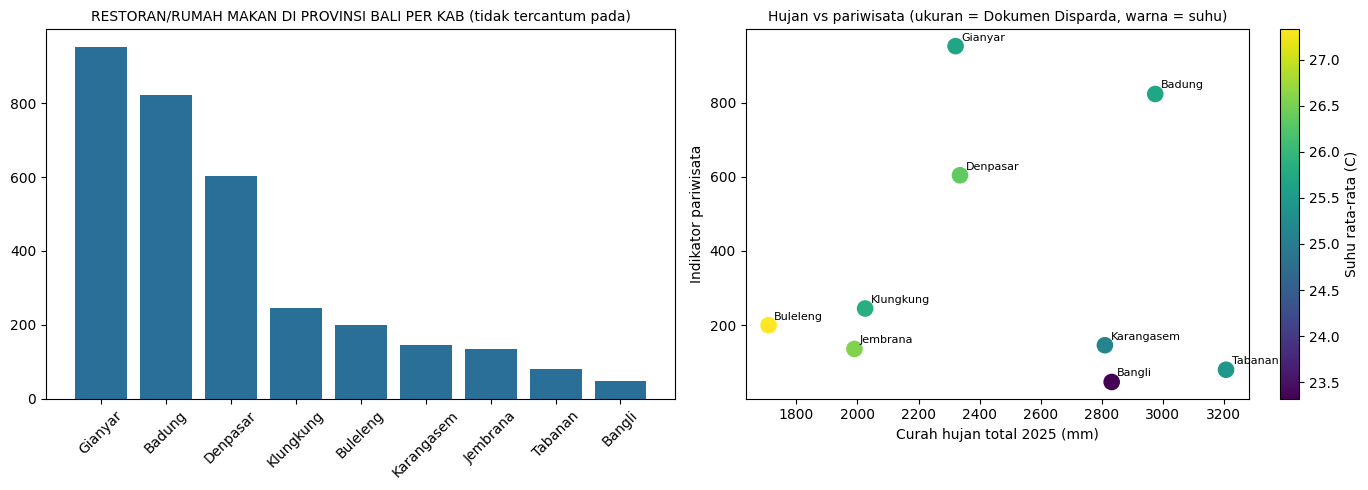

Korelasi (Pearson):


,indikator_pariwisata,suhu_rata2_C,hujan_total_mm,hari_hujan
indikator_pariwisata,1.00,0.20,0.00,0.01
suhu_rata2_C,0.20,1.00,-0.67,-0.89
hujan_total_mm,0.00,-0.67,1.00,0.88
hari_hujan,0.01,-0.89,0.88,1.00


Makna scrape_1..3: {'scrape_1': 'Jumlah Dokumen Terkait Wilayah di Portal', 'scrape_2': 'Tautan Informasi Tambahan', 'scrape_3': 'Status Scraping'}


In [ ]:
# Visualisasi hasil gabungan resmi
g = gabungan.sort_values("indikator_pariwisata", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(g["kunci_wilayah"].str.title(), g["indikator_pariwisata"], color="#2a6f97")
ax[0].set_title(f"{INFO_INDIKATOR["kolom"][:45]} ({INFO_INDIKATOR["satuan"][:20]})", fontsize=10)
ax[0].tick_params(axis="x", rotation=45)

ukuran = (g["scrape_1"] / g["scrape_1"].max() * 600 + 40) if g["scrape_1"].notna().any() and g["scrape_1"].max() > 0 else 120
sc = ax[1].scatter(g["hujan_total_mm"], g["indikator_pariwisata"], s=ukuran, c=g["suhu_rata2_C"], cmap="viridis")
for _, rr in g.iterrows():
    ax[1].annotate(rr["kunci_wilayah"].title(), (rr["hujan_total_mm"], rr["indikator_pariwisata"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel("Curah hujan total 2025 (mm)")
ax[1].set_ylabel("Indikator pariwisata")
ax[1].set_title("Hujan vs pariwisata (ukuran = Dokumen Disparda, warna = suhu)", fontsize=10)
plt.colorbar(sc, ax=ax[1], label="Suhu rata-rata (C)")
plt.tight_layout()
plt.savefig(PROC / "visual_gabungan.png", dpi=150)
plt.show()

kolom_korelasi = [c for c in gabungan.select_dtypes("number").columns if gabungan[c].nunique() > 1]
print("Korelasi (Pearson):")
display(gabungan[kolom_korelasi].corr().round(2))
print("Makna scrape_1..3:", KET_KOLOM_SCRAPE)

### Kesimpulan & catatan
- Tiga sumber (**berkas data Disparda**, **API Open-Meteo**, dan **data listing resmi portal Disparda Bali**) digabung lewat `kunci_wilayah` dengan `validate="one_to_one"`; tidak ada duplikasi baris.
- Aturan & Etika: **Sesuai dengan ketentuan tugas, data Wikipedia tidak digunakan.** Seluruh data tambahan bersumber resmi dari portal Dinas Pariwisata Provinsi Bali (`https://disparda.baliprov.go.id/data-statistik`).
- Keterbatasan: Jumlah sampel (n) hanya 9 wilayah, sehingga korelasi yang dihasilkan bersifat deskriptif dan bukan bukti hubungan kausal; cuaca diambil pada titik koordinat ibu kota kabupaten/kota; tahun data berkas Disparda, rujukan dokumen portal, dan data cuaca (2025) dapat memiliki perbedaan periode pelaporan.
- Atribusi: Dinas Pariwisata Provinsi Bali (hak cipta Pemerintah Provinsi Bali), dan Open-Meteo (CC BY 4.0).

## Unduh hasil (untuk upload ke GitHub / ELSA)
Mengemas `data/raw`, `Process`, dan `docs` menjadi satu zip. Di Colab, zip langsung terunduh.

In [ ]:
import shutil
from pathlib import Path

# Hapus zip lama jika ada
for f in Path(".").glob("*.zip"):
    f.unlink()

tmp = Path("bundling_uts_resmi")
shutil.rmtree(tmp, ignore_errors=True)
tmp.mkdir()

# Menyalin folder kerja penting
for folder in ["data", "Process", "docs"]:
    shutil.copytree(folder, tmp / folder)

# Memastikan berkas wikipedia lama di dalam folder sementara ikut dibersihkan agar tidak masuk ke berkas ZIP akhir
for f_temp in tmp.rglob("*scrape_bersih*"):
    f_temp.unlink()

# Kompres menjadi ZIP resmi
shutil.make_archive("arsip_lengkap_UTS_DAM_2501010174", "zip", root_dir=tmp)
shutil.rmtree(tmp, ignore_errors=True)

print("Zip resmi berhasil dibuat:", Path("arsip_lengkap_UTS_DAM_2501010174.zip").stat().st_size, "byte")
if IN_COLAB:
    from google.colab import files
    files.download("arsip_lengkap_UTS_DAM_2501010174.zip")

Zip resmi berhasil dibuat: 277921 byte


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>